# 주택 가격 예측하기

메인퀘스트에 오신 것을 환영합니다!

이번 퀘스트의 목표는 여러 특성들을 종합적으로 고려하여 가장 주택 가격을 잘 예측하는 회귀모델을 만드는 것입니다.

- 예측할 값(y): SalePrice
- 평가지표: RMSE

예시 형식:
~~~
Id,SalePrice
1461,169000.1
1462,187724.1233
1463,175221
etc.
~~~

### 데이터 불러오기

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.tree import DecisionTreeRegressor

# 한글 폰트 (있는 것 중 첫 번째 사용)
for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic']:
    if f in {x.name for x in font_manager.fontManager.ttflist}:
        plt.rcParams['font.family'] = f
        break
plt.rcParams['axes.unicode_minus'] = False

train_df = pd.read_csv('./train.csv')
test_df = pd.read_csv('./test.csv')
print('train:', train_df.shape, '| test:', test_df.shape)

train: (1168, 81) | test: (292, 80)


특성이 너무 많습니다! 어떻게 하면 좋을까요?

참고로 각각의 특성은 다음을 나타냅니다.

| 변수명               | 설명 (한국어)                         |
| ----------------- | -------------------------------- |
| **SalePrice**     | 주택의 판매 가격(달러). 예측해야 하는 타겟 변수     |
| **MSSubClass**    | 건물 등급(건물 종류 분류)                  |
| **MSZoning**      | 토지 용도 구분(일반적인 구역 분류)             |
| **LotFrontage**   | 도로에 접한 토지 길이 (피트 단위)             |
| **LotArea**       | 토지 면적 (평방 피트)                    |
| **Street**        | 도로 접근 방식                         |
| **Alley**         | 골목(후면 도로) 접근 방식                  |
| **LotShape**      | 토지의 전반적인 모양                      |
| **LandContour**   | 토지의 평탄도                          |
| **Utilities**     | 사용 가능한 공공시설(전기, 수도 등)            |
| **LotConfig**     | 토지 배치 형태                         |
| **LandSlope**     | 토지의 경사도                          |
| **Neighborhood**  | Ames 시 내의 물리적 위치(주변 지역)          |
| **Condition1**    | 주요 도로·철도에 대한 근접도                 |
| **Condition2**    | 두 번째 주요 도로·철도에 대한 근접도            |
| **BldgType**      | 주거 건물 유형 (단독, 다세대 등)             |
| **HouseStyle**    | 주택의 건축 양식                        |
| **OverallQual**   | 자재 및 마감 품질 종합 평가                 |
| **OverallCond**   | 주택의 전반적인 상태 평가                   |
| **YearBuilt**     | 최초 건축 연도                         |
| **YearRemodAdd**  | 리모델링/개조 연도                       |
| **RoofStyle**     | 지붕 스타일                           |
| **RoofMatl**      | 지붕 재료                            |
| **Exterior1st**   | 외장 마감재(주 재료)                     |
| **Exterior2nd**   | 외장 마감재(보조 재료, 2번째)               |
| **MasVnrType**    | 석조 베니어 타입                        |
| **MasVnrArea**    | 석조 베니어 면적 (평방 피트)                |
| **ExterQual**     | 외장재 품질 평가                        |
| **ExterCond**     | 외장재 상태 평가                        |
| **Foundation**    | 기초(Foundation) 유형                |
| **BsmtQual**      | 지하실 높이 평가                        |
| **BsmtCond**      | 지하실 상태 평가                        |
| **BsmtExposure**  | 지하실 외부 노출 여부(출입구/창문 등)           |
| **BsmtFinType1**  | 주요 지하실 마감 구역 유형                  |
| **BsmtFinSF1**    | 주요 지하실 마감 면적 (평방 피트)             |
| **BsmtFinType2**  | 보조 지하실 마감 구역 유형                  |
| **BsmtFinSF2**    | 보조 지하실 마감 면적 (평방 피트)             |
| **BsmtUnfSF**     | 미완성 지하실 면적 (평방 피트)               |
| **TotalBsmtSF**   | 지하실 전체 면적 (평방 피트)                |
| **Heating**       | 난방 시스템 종류                        |
| **HeatingQC**     | 난방 품질 및 상태                       |
| **CentralAir**    | 중앙 에어컨 설치 여부                     |
| **Electrical**    | 전기 시스템 종류                        |
| **1stFlrSF**      | 1층 면적 (평방 피트)                    |
| **2ndFlrSF**      | 2층 면적 (평방 피트)                    |
| **LowQualFinSF**  | 저품질 마감 공간 면적 (전체 층 합산)           |
| **GrLivArea**     | 지상(Above grade) 생활 공간 면적 (평방 피트) |
| **BsmtFullBath**  | 지하실 완비 욕실 수                      |
| **BsmtHalfBath**  | 지하실 반 욕실 수                       |
| **FullBath**      | 지상 완비 욕실 수                       |
| **HalfBath**      | 지상 반 욕실 수                        |
| **Bedroom**       | 지하실 제외 침실 수                      |
| **Kitchen**       | 주방 수                             |
| **KitchenQual**   | 주방 품질                            |
| **TotRmsAbvGrd**  | 지상 전체 방 개수 (욕실 제외)               |
| **Functional**    | 주택 기능성 평가                        |
| **Fireplaces**    | 벽난로 개수                           |
| **FireplaceQu**   | 벽난로 품질                           |
| **GarageType**    | 차고 위치(유형)                        |
| **GarageYrBlt**   | 차고 건축 연도                         |
| **GarageFinish**  | 차고 내부 마감 상태                      |
| **GarageCars**    | 차고 크기 (주차 가능 차량 수)               |
| **GarageArea**    | 차고 면적 (평방 피트)                    |
| **GarageQual**    | 차고 품질                            |
| **GarageCond**    | 차고 상태                            |
| **PavedDrive**    | 포장 진입로 여부                        |
| **WoodDeckSF**    | 목재 데크 면적 (평방 피트)                 |
| **OpenPorchSF**   | 오픈 현관 면적 (평방 피트)                 |
| **EnclosedPorch** | 밀폐된 현관 면적 (평방 피트)                |
| **3SsnPorch**     | 3계절용 현관 면적 (평방 피트)               |
| **ScreenPorch**   | 스크린 현관 면적 (평방 피트)                |
| **PoolArea**      | 수영장 면적 (평방 피트)                   |
| **PoolQC**        | 수영장 품질                           |
| **Fence**         | 울타리 품질                           |
| **MiscFeature**   | 기타 특수 기능                         |
| **MiscVal**       | 기타 기능의 금전적 가치                    |
| **MoSold**        | 판매 월                             |
| **YrSold**        | 판매 연도                            |
| **SaleType**      | 판매 유형                            |
| **SaleCondition** | 판매 조건                            |

## 1. 데이터 탐색

#### 1. SalePrice 분포

- 집값은 오른쪽으로 치우친 분포입니다. 대부분은 15만 달러 안팎에 몰려 있고, 소수의 고가 주택이 긴 꼬리를 만듭니다.
- 그래서 로그 변환(`log1p`)을 하면 분포가 훨씬 대칭에 가까워집니다. 모델링 시 로그 변환을 고려합니다.

#### 2. EDA 대상 피처 선정

수치형과 범주형을 각각 다른 기준으로 보고, 집값과의 관계가 큰 피처를 골랐습니다.

1. **상관계수 (수치형)**: `SalePrice`와의 상관계수 절댓값이 큰 피처를 선택했습니다. `OverallQual`(0.785), `GrLivArea`(0.71), `GarageCars`(0.633)가 상위입니다.
2. **eta² (범주형)**: 범주별 집값 차이를 설명하는 비율이 큰 피처를 선택했습니다. `Neighborhood`(0.529), `ExterQual`(0.478), `KitchenQual`(0.466), `BsmtQual`(0.418)이 상위입니다.

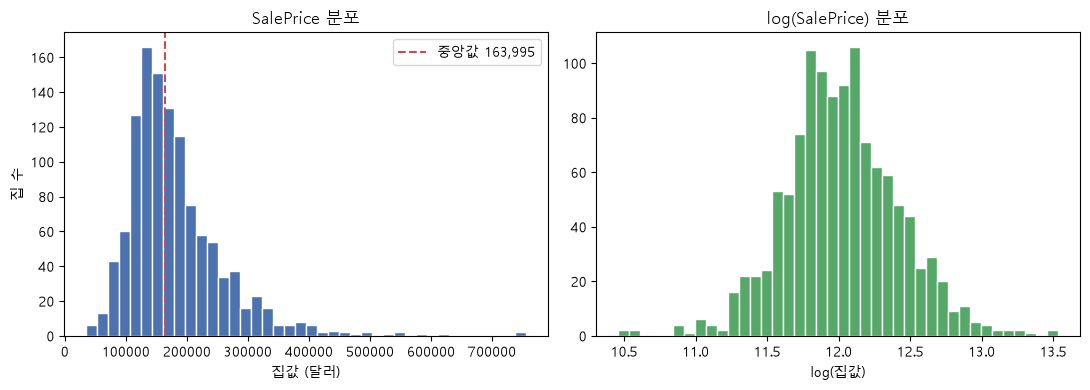

In [2]:
# 집값 분포

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(train_df['SalePrice'], bins=40, color='#4C72B0', edgecolor='white')
axes[0].axvline(train_df['SalePrice'].median(), color='#C44E52', ls='--',
                label=f"중앙값 {train_df['SalePrice'].median():,.0f}")
axes[0].set_title('SalePrice 분포')
axes[0].set_xlabel('집값 (달러)')
axes[0].set_ylabel('집 수')
axes[0].legend()

axes[1].hist(np.log1p(train_df['SalePrice']), bins=40, color='#55A868', edgecolor='white')
axes[1].set_title('log(SalePrice) 분포')
axes[1].set_xlabel('log(집값)')

plt.tight_layout()
plt.show()

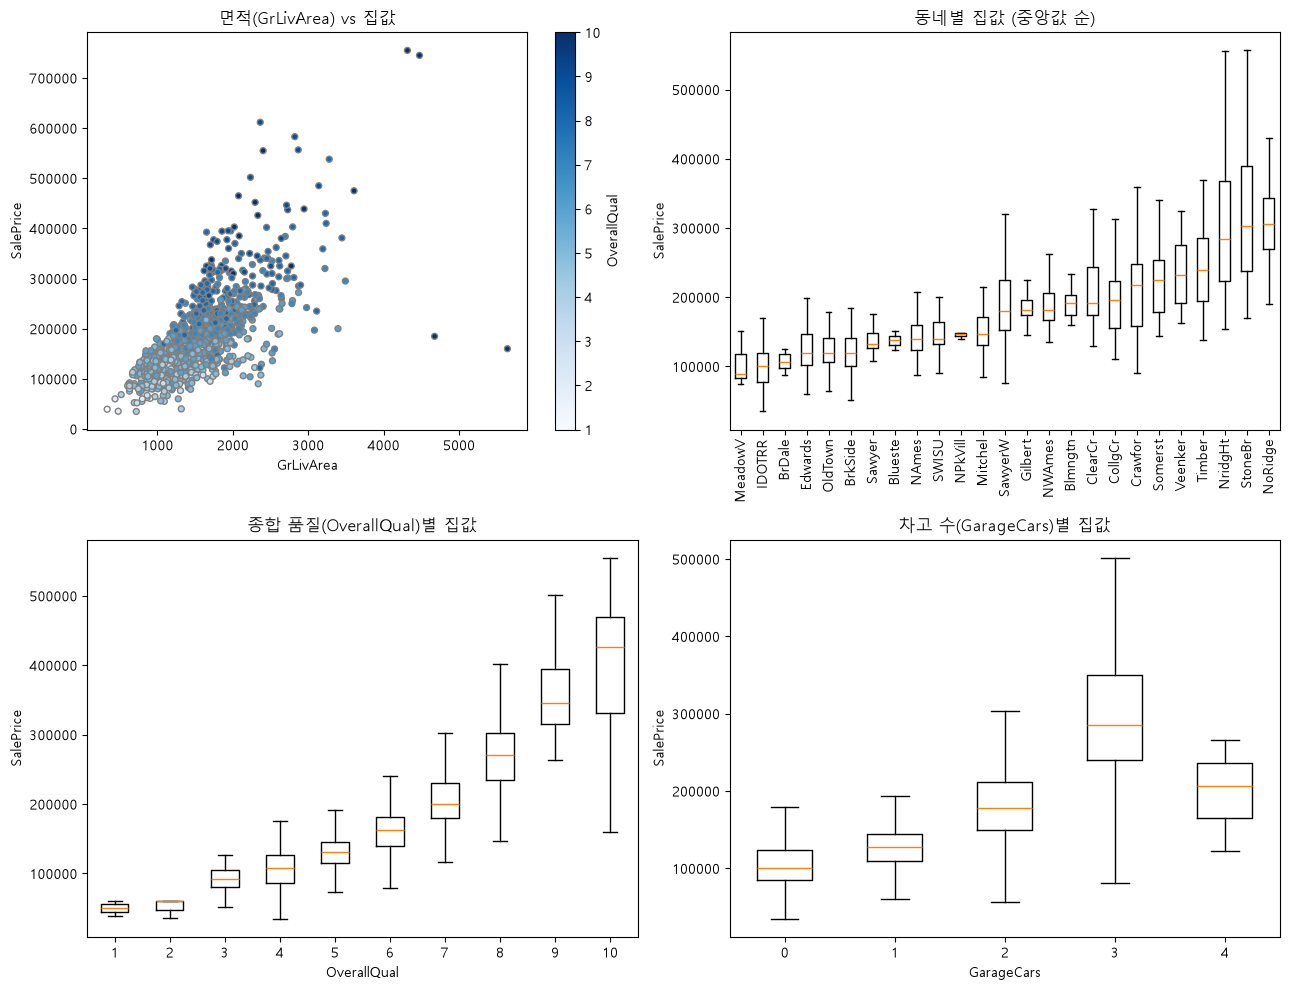

In [3]:
#  예상 주요 피처와 집값의 관계

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# (1) 면적 vs 집값 (색 = 종합 품질)
ax = axes[0, 0]
sc = ax.scatter(train_df['GrLivArea'], train_df['SalePrice'],
                c=train_df['OverallQual'], cmap='Blues', edgecolor='gray', s=18)
ax.set_title('면적(GrLivArea) vs 집값')
ax.set_xlabel('GrLivArea')
ax.set_ylabel('SalePrice')
fig.colorbar(sc, ax=ax, label='OverallQual')

# (2) 동네별 집값 (중앙값 순)
ax = axes[0, 1]
order = train_df.groupby('Neighborhood')['SalePrice'].median().sort_values().index
ax.boxplot([train_df.loc[train_df['Neighborhood'] == n, 'SalePrice'] for n in order],
           tick_labels=order, showfliers=False)
ax.set_title('동네별 집값 (중앙값 순)')
ax.set_ylabel('SalePrice')
ax.tick_params(axis='x', rotation=90)

# (3) 종합 품질별 집값
ax = axes[1, 0]
q = sorted(train_df['OverallQual'].unique())
ax.boxplot([train_df.loc[train_df['OverallQual'] == v, 'SalePrice'] for v in q],
           tick_labels=q, showfliers=False)
ax.set_title('종합 품질(OverallQual)별 집값')
ax.set_xlabel('OverallQual')
ax.set_ylabel('SalePrice')

# (4) 차고 수별 집값
ax = axes[1, 1]
cars = sorted(train_df['GarageCars'].unique())
ax.boxplot([train_df.loc[train_df['GarageCars'] == v, 'SalePrice'] for v in cars],
           tick_labels=cars, showfliers=False)
ax.set_title('차고 수(GarageCars)별 집값')
ax.set_xlabel('GarageCars')
ax.set_ylabel('SalePrice')

plt.tight_layout()
plt.show()

In [4]:
num = train_df.select_dtypes(include='number').drop(columns=['Id'])
corr = num.corr()['SalePrice'].drop('SalePrice').sort_values(ascending=False)

corr_table = pd.DataFrame({
    'corr_with_SalePrice': corr.round(3),
    'abs_corr': corr.abs().round(3),
}).sort_values('abs_corr', ascending=False)

print(f"수치형 피처 {len(corr_table)}개와 SalePrice의 상관계수")
corr_table.head(10)

수치형 피처 36개와 SalePrice의 상관계수


,corr_with_SalePrice,abs_corr
OverallQual,0.785,0.785
GrLivArea,0.710,0.710
GarageCars,0.633,0.633
GarageArea,0.618,0.618
1stFlrSF,0.598,0.598
TotalBsmtSF,0.596,0.596
FullBath,0.578,0.578
TotRmsAbvGrd,0.549,0.549
YearRemodAdd,0.505,0.505
YearBuilt,0.502,0.502


In [5]:
y = train_df['SalePrice']
ss_tot = ((y - y.mean()) ** 2).sum()

cat_cols = train_df.select_dtypes(include=['object', 'str']).columns
rows = []
for c in cat_cols:
    g = train_df.groupby(c)['SalePrice']
    ss_between = (g.count() * (g.mean() - y.mean()) ** 2).sum()
    rows.append({
        'feature': c,
        'n_categories': train_df[c].nunique(),
        'eta2': round(ss_between / ss_tot, 3),
        'median_max': round(g.median().max()),
        'median_min': round(g.median().min()),
    })

cat_effect = pd.DataFrame(rows).sort_values('eta2', ascending=False)
print(f"범주형 피처 {len(cat_effect)}개의 집값 차이 (eta2 높은 순)")
cat_effect.head(10)

범주형 피처 43개의 집값 차이 (eta2 높은 순)


,feature,n_categories,eta2,median_max,median_min
8,Neighborhood,25,0.529,306000,88500
18,ExterQual,4,0.478,341250,81000
30,KitchenQual,4,0.466,313000,115000
21,BsmtQual,4,0.418,314813,114000
34,GarageFinish,3,0.249,214000,135000
20,Foundation,6,0.245,203000,101800
33,GarageType,6,0.195,223750,108000
27,HeatingQC,5,0.194,194350,87000
24,BsmtFinType1,6,0.180,211000,137450
32,FireplaceQu,5,0.171,306000,129000


#### 3. 치우친 수치형 변수

- 집값뿐 아니라 일부 면적·금액 변수도 값이 한쪽으로 심하게 치우쳐 있습니다. (`LotArea`, `MiscVal`, `PoolArea` 등: 대부분 작고 소수만 극단적으로 큼)
- 이런 변수는 소수의 극단값이 선형 모델을 끌고 가기 때문에 **로그 변환**으로 눌러 줍니다. (전처리에서 적용)

왜도(skewness) 상위 8개 — 0에 가까울수록 대칭, 클수록 오른쪽으로 치우침
MiscVal         22.1
PoolArea        14.4
LotArea         11.1
3SsnPorch       11.1
LowQualFinSF     9.6
BsmtFinSF2       4.5
KitchenAbvGr     4.5
BsmtHalfBath     4.1
dtype: float64


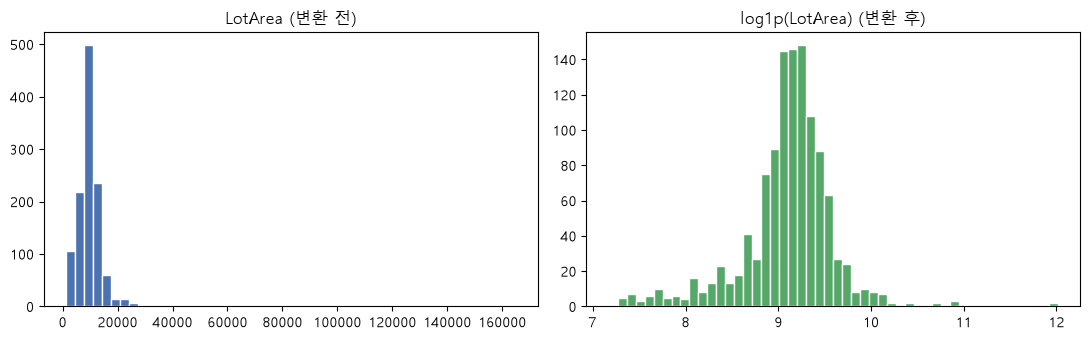

In [6]:
skew = train_df.select_dtypes('number').drop(columns=['Id', 'SalePrice']).skew().sort_values(ascending=False)
print('왜도(skewness) 상위 8개 — 0에 가까울수록 대칭, 클수록 오른쪽으로 치우침')
print(skew.head(8).round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(train_df['LotArea'], bins=50, color='#4C72B0', edgecolor='white')
axes[0].set_title('LotArea (변환 전)')
axes[1].hist(np.log1p(train_df['LotArea']), bins=50, color='#55A868', edgecolor='white')
axes[1].set_title('log1p(LotArea) (변환 후)')
plt.tight_layout(); plt.show()

## 2. 데이터 전처리

### 2.1. 이상치

- 값이 큰 행은 대부분 희귀한 특성(대형 주택 등)을 가진 실제 매물이라 제거하지 않습니다.
- 다만 `Id` 1299, 524는 **면적(`GrLivArea` 4,000 이상)과 품질은 최상급인데 가격이 낮은** `Partial`(미완공 판매) 거래입니다. 면적-가격 관계에서 확실히 벗어나 선형 모델을 크게 흔들기 때문에 **학습 데이터에서 제거**합니다. (테스트 데이터에는 `GrLivArea` 4,000 이상인 집이 없습니다.)

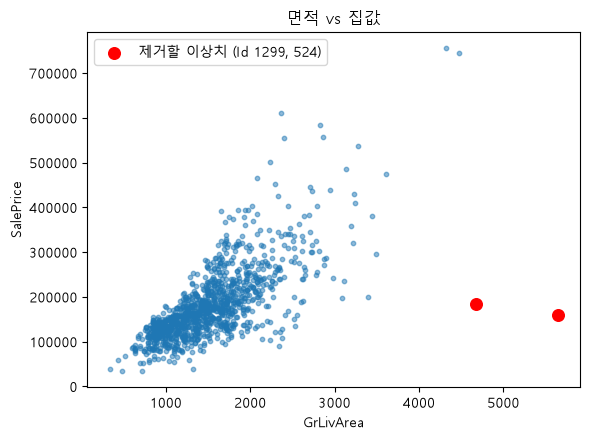

테스트의 GrLivArea 최대값: 3627


In [7]:
out_ = train_df['Id'].isin([1299, 524])
plt.figure(figsize=(6, 4.5))
plt.scatter(train_df.loc[~out_, 'GrLivArea'], train_df.loc[~out_, 'SalePrice'], s=10, alpha=.5)
plt.scatter(train_df.loc[out_, 'GrLivArea'], train_df.loc[out_, 'SalePrice'], s=70, c='red', label='제거할 이상치 (Id 1299, 524)')
plt.xlabel('GrLivArea'); plt.ylabel('SalePrice'); plt.legend(); plt.title('면적 vs 집값')
plt.tight_layout(); plt.show()
print('테스트의 GrLivArea 최대값:', test_df['GrLivArea'].max())

### 2.2. 결측치 · 인코딩 · 로그 변환

결측이 무엇을 뜻하는지 먼저 확인하고, 뜻에 맞게 채웁니다. 학습·테스트를 **한 함수로 같이** 처리해서 컬럼이 어긋나지 않게 합니다. (타깃은 쓰지 않으므로 누수는 없습니다.)

**수치형**
- `GarageYrBlt`(차고 없음) → **`YearBuilt`(집 지은 연도)로 채움.** 0으로 두면 1980 같은 연도 사이에 0이 섞여 선형 모델에 극단값이 됩니다.
- `MasVnrArea`(장식 없음) → 0, `LotFrontage`(기록 누락) → 같은 동네(`Neighborhood`) 중앙값

**범주형**
- 결측 대부분은 "없음"을 뜻하므로 `None`으로 채웁니다. (`Electrical`의 실제 결측 1개는 최빈값)
- 순서가 있는 열(품질·노출·마감)은 숫자로: `Ex=5, Gd=4, TA=3, Fa=2, Po=1, None=0`
- 순서가 없는 열은 원-핫 인코딩합니다.
- **`MSSubClass`(건물 등급 코드), `MoSold`(판매 월)는 값이 숫자지만 크기 의미가 없는 범주**이므로 문자열로 바꿔 원-핫 인코딩합니다.

**로그 변환**
- 왜도(치우침)가 **2를 넘는 극단적인 수치형 변수만** `log1p`로 변환합니다.
- 타깃 `SalePrice`도 `log1p`로 변환해서 학습하고, 예측 후 `expm1`로 되돌립니다.

**스케일링**: 규제(Ridge/Lasso)는 변수 크기에 민감하므로 모델 안에서 `StandardScaler`를 적용합니다. (트리는 필요 없음)

In [8]:
QUAL = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}
BSMT_FIN = {'GLQ': 6, 'ALQ': 5, 'BLQ': 4, 'Rec': 3, 'LwQ': 2, 'Unf': 1, 'None': 0}
ORDINAL_MAPS = {
    'ExterQual': QUAL, 'ExterCond': QUAL, 'HeatingQC': QUAL, 'KitchenQual': QUAL,
    'BsmtQual': QUAL, 'BsmtCond': QUAL, 'FireplaceQu': QUAL, 'GarageQual': QUAL,
    'GarageCond': QUAL, 'PoolQC': QUAL,
    'BsmtExposure': {'Gd': 4, 'Av': 3, 'Mn': 2, 'No': 1, 'None': 0},
    'BsmtFinType1': BSMT_FIN, 'BsmtFinType2': BSMT_FIN,
    'GarageFinish': {'Fin': 3, 'RFn': 2, 'Unf': 1, 'None': 0},
    'PavedDrive': {'Y': 2, 'P': 1, 'N': 0},
    'CentralAir': {'Y': 1, 'N': 0},
}
CODE_COLS = ['MSSubClass', 'MoSold']          # 숫자로 저장된 범주형

def make_features(tr_raw, te_raw, skew_thr=2.0):
    df = pd.concat([tr_raw.drop(columns='SalePrice'), te_raw], ignore_index=True)

    # 수치형 결측
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])   # 차고 없음 → 집 지은 연도
    df['MasVnrArea'] = df['MasVnrArea'].fillna(0)
    df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(lambda s: s.fillna(s.median()))
    df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].median())

    # 범주형 결측 → 'None' (Electrical만 최빈값), 순서형 → 숫자
    df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])
    cat_cols = list(df.select_dtypes(include=['object', 'str']).columns)
    df[cat_cols] = df[cat_cols].fillna('None')
    for col, m in ORDINAL_MAPS.items():
        df[col] = df[col].map(m)

    # 숫자 코드 범주형(MSSubClass, MoSold) → 문자열 → 원-핫 대상
    for c in CODE_COLS:
        df[c] = df[c].astype(str)
    nominal = [c for c in cat_cols if c not in ORDINAL_MAPS] + CODE_COLS

    # 극단적으로 치우친 수치형 → log1p
    logged = []
    if skew_thr is not None:
        skip = set(ORDINAL_MAPS) | {'Id', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'YrSold', 'OverallQual', 'OverallCond'}
        for c in df.select_dtypes('number').columns:
            if c not in skip and df[c].nunique() > 2 and abs(df[c].skew()) > skew_thr:
                df[c] = np.log1p(df[c]); logged.append(c)

    df = pd.get_dummies(df, columns=nominal, dtype=int)
    df = df.fillna(df.median(numeric_only=True))      # 테스트에만 있는 소수의 수치 결측

    n = len(tr_raw)
    return df.iloc[:n].drop(columns='Id'), df.iloc[n:].drop(columns='Id'), te_raw['Id'].values, logged

X_all, X_test, test_ids, logged = make_features(train_df, test_df)

# 이상치 2행은 학습 데이터에서만 제거 (테스트는 그대로)
drop_mask = train_df['Id'].isin([1299, 524]).values
X = X_all[~drop_mask].reset_index(drop=True)
y = train_df['SalePrice'].values[~drop_mask]
ylog = np.log1p(y)

print('X:', X.shape, '| X_test:', X_test.shape, '| 결측:', int(X.isna().sum().sum()), int(X_test.isna().sum().sum()))
print('제거한 행:', int(drop_mask.sum()), '| log1p 변환한 열:', logged)

X: (1166, 265) | X_test: (292, 265) | 결측: 0 0
제거한 행: 2 | log1p 변환한 열: ['LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF2', 'LowQualFinSF', 'BsmtHalfBath', 'KitchenAbvGr', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal']


## 3. 모델 학습 · 비교

### 3.1. 구성

| 모델 | 입력 | 타깃 | 비고 |
|---|---|---|---|
| 선형회귀 (원래 가격) | 전체 피처 | 가격 | 기준선 |
| 선형회귀 (log 가격) | 전체 피처 | log 가격 | 로그 타깃 효과 확인 |
| **Ridge** + 3차 다항식 | 전체 피처 + 핵심 8개 3차 다항식 | log 가격 | 규제(L2), 규제 강도 `alpha`는 교차검증으로 선택 |
| **Lasso** + 3차 다항식 | 위와 동일 | log 가격 | 규제(L1), 불필요한 변수의 계수를 0으로 만듦 |
| **Decision Tree** | 전체 피처 | log 가격 | `max_depth`, `min_samples_leaf`를 GridSearch로 조정 |

- **다항식**: 전체 피처를 다 확장하면 열이 폭발하므로, 집값과 관계가 큰 수치형 8개만 3차까지 확장합니다. (품질·면적이 높을수록 가격이 가파르게 오르는 곡선 관계를 선형 모델이 잡게 하려는 목적)
- **검증**: ① 학습 데이터의 20%를 **검증셋(Validation Set)** 으로 떼어 확인하고, ② 표본이 작아 점수가 흔들리므로 **5-fold 교차검증(CV)** 도 함께 봅니다. 평가지표는 대회와 같은 **원래 가격 기준 RMSE**입니다.

In [9]:
POLY_COLS = ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'GarageCars',
             'YearBuilt', 'FullBath', '1stFlrSF', 'LotArea']

def add_poly(Xdf, deg=3):
    P = PolynomialFeatures(degree=deg, include_bias=False).fit_transform(Xdf[POLY_COLS])
    poly_df = pd.DataFrame(P, index=Xdf.index, columns=[f'poly_{i}' for i in range(P.shape[1])])
    return pd.concat([Xdf, poly_df], axis=1)

X_poly = add_poly(X)

def make_ridge():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40)))

def make_lasso():
    return make_pipeline(StandardScaler(), LassoCV(alphas=np.logspace(-4, -1, 20), cv=3, max_iter=20000, random_state=0))

def make_tree():
    return GridSearchCV(DecisionTreeRegressor(random_state=42),
                        {'max_depth': [3, 4, 5, 6, 8, 10, None], 'min_samples_leaf': [1, 3, 5, 10, 20]},
                        cv=5, scoring='neg_mean_squared_error')

MODELS = {   # 이름: (모델 생성 함수, 입력 데이터, 타깃)
    '선형회귀 (원래 가격)': (LinearRegression, 'plain', 'raw'),
    '선형회귀 (log 가격)':  (LinearRegression, 'plain', 'log'),
    'Ridge + 3차 다항식':   (make_ridge,       'poly',  'log'),
    'Lasso + 3차 다항식':   (make_lasso,       'poly',  'log'),
    'Decision Tree':        (make_tree,        'plain', 'log'),
}

def fit_predict(name, tr, te):
    """tr 행으로 학습 → te 행 예측. 항상 log 가격 단위로 돌려준다."""
    make, data, target = MODELS[name]
    D = X_poly if data == 'poly' else X
    t = ylog if target == 'log' else y
    model = make().fit(D.iloc[tr], t[tr])
    p = model.predict(D.iloc[te])
    return model, (np.log1p(np.clip(p, 1, None)) if target == 'raw' else p)

def rmse_usd(p_log, true_usd):
    return float(np.sqrt(np.mean((np.expm1(p_log) - true_usd) ** 2)))

def rmse_log(p_log, true_log):
    return float(np.sqrt(np.mean((p_log - true_log) ** 2)))

# (1) 검증셋: 학습 80% / 검증 20%
idx_tr, idx_va = train_test_split(np.arange(len(X)), test_size=0.2, random_state=42)
val_pred, fitted = {}, {}
for name in MODELS:
    fitted[name], val_pred[name] = fit_predict(name, idx_tr, idx_va)

# (2) 5-fold 교차검증
cv_pred = {name: np.zeros(len(X)) for name in MODELS}
for tr, te in KFold(5, shuffle=True, random_state=42).split(X):
    for name in MODELS:
        cv_pred[name][te] = fit_predict(name, tr, te)[1]

def show(names):
    return pd.DataFrame({
        '모델': names,
        '검증셋 RMSE($)': [round(rmse_usd(val_pred[n], y[idx_va])) for n in names],
        'CV RMSE($)':     [round(rmse_usd(cv_pred[n], y)) for n in names],
        'CV RMSE(log)':   [round(rmse_log(cv_pred[n], ylog), 4) for n in names],
    })

show(list(MODELS))

,모델,검증셋 RMSE($),CV RMSE($),CV RMSE(log)
0,선형회귀 (원래 가격),26399,29869,0.5609
1,선형회귀 (log 가격),21552,21883,0.1255
2,Ridge + 3차 다항식,19333,20283,0.1126
3,Lasso + 3차 다항식,19457,20360,0.1118
4,Decision Tree,34614,36162,0.1849


In [10]:
lasso = fitted['Lasso + 3차 다항식'][-1]
tree = fitted['Decision Tree']
print('Ridge 선택된 alpha:', round(fitted['Ridge + 3차 다항식'][-1].alpha_, 1))
print('Lasso 선택된 alpha:', round(lasso.alpha_, 4), '| 계수가 0이 아닌 피처:', int((lasso.coef_ != 0).sum()), '/', X_poly.shape[1])
print('Decision Tree 최적 설정:', tree.best_params_)

Ridge 선택된 alpha: 289.4
Lasso 선택된 alpha: 0.0038 | 계수가 0이 아닌 피처: 96 / 429
Decision Tree 최적 설정: {'max_depth': 10, 'min_samples_leaf': 10}


**읽는 법**

- 선형회귀를 원래 가격에서 **log 가격**으로 바꾸는 것만으로 오차가 크게 줄어듭니다. 집값이 오른쪽으로 치우친 분포라서 비싼 집이 모델을 끌고 가는 것을 막아 주기 때문입니다.
- **Ridge/Lasso + 다항식**은 여기서 한 번 더 줄입니다. 변수가 400개를 넘기 때문에 규제가 과적합을 막아 줍니다. Lasso는 이 중 일부 피처만 남깁니다.
- **Decision Tree**는 깊이를 조정해도 선형 모델보다 크게 못합니다. 트리 1개는 가격을 계단식으로만 예측해서, 면적·품질에 따라 부드럽게 오르는 집값 구조를 잡기 어렵습니다.

### 3.2. 앙상블

서로 다른 방식의 모델을 **log 가격 단위에서 가중 평균**합니다. 단일 모델과 같은 기준(검증셋 · CV)으로 비교하고, **CV RMSE가 가장 낮은 앙상블**을 최종 모델로 씁니다. (검증셋은 234행뿐이라 흔들리므로 선택은 CV 기준)

In [11]:
ENSEMBLES = {   # 이름: {모델: 가중치}
    'Ridge + Lasso':                   {'Ridge + 3차 다항식': .5, 'Lasso + 3차 다항식': .5},
    'Lasso + Decision Tree (0.8:0.2)': {'Lasso + 3차 다항식': .8, 'Decision Tree': .2},
    'Ridge + Lasso + Decision Tree':   {'Ridge + 3차 다항식': .4, 'Lasso + 3차 다항식': .4, 'Decision Tree': .2},
}
for ens, w in ENSEMBLES.items():
    val_pred[ens] = sum(wt * val_pred[m] for m, wt in w.items())
    cv_pred[ens] = sum(wt * cv_pred[m] for m, wt in w.items())

show(['Ridge + 3차 다항식', 'Lasso + 3차 다항식', 'Decision Tree'] + list(ENSEMBLES))

,모델,검증셋 RMSE($),CV RMSE($),CV RMSE(log)
0,Ridge + 3차 다항식,19333,20283,0.1126
1,Lasso + 3차 다항식,19457,20360,0.1118
2,Decision Tree,34614,36162,0.1849
3,Ridge + Lasso,19203,20113,0.1112
4,Lasso + Decision Tree (0.8:0.2),19237,20363,0.1130
5,Ridge + Lasso + Decision Tree,19139,20229,0.1127


**읽는 법**

- 성격이 비슷한 **Ridge와 Lasso를 섞은 앙상블**은 CV에서 단일 모델보다 소폭 좋아집니다. 둘이 틀리는 방향이 조금씩 달라서 오차가 일부 상쇄됩니다.
- **Decision Tree를 섞으면** 가중치를 20%만 줘도 CV 기준으로 이득이 없거나 오히려 나빠집니다. 앙상블은 "약한 모델이라도 틀리는 방향이 다르면 도움이 된다"가 원리지만, 트리가 선형 모델보다 **너무 못하면** 평균하면서 오차만 끌어올립니다.

### 3.3. 로그 변환 효과 확인 (모델 개선)

전처리에서 추가한 **극단적 수치형 로그 변환**이 실제로 도움이 됐는지 Ridge + 다항식으로 전/후를 비교합니다. (같은 설정, 변환만 다름)

In [12]:
def quick_eval(skew_thr):
    Xa, _, _, cols = make_features(train_df, test_df, skew_thr=skew_thr)
    Xa = Xa[~drop_mask].reset_index(drop=True)
    Xp = add_poly(Xa)
    va = make_ridge().fit(Xp.iloc[idx_tr], ylog[idx_tr]).predict(Xp.iloc[idx_va])
    cv = np.zeros(len(Xa))
    for tr, te in KFold(5, shuffle=True, random_state=42).split(Xa):
        cv[te] = make_ridge().fit(Xp.iloc[tr], ylog[tr]).predict(Xp.iloc[te])
    return len(cols), round(rmse_usd(va, y[idx_va])), round(rmse_usd(cv, y)), round(rmse_log(cv, ylog), 4)

log_cmp = pd.DataFrame(
    [('변환 없음',) + quick_eval(None), ('왜도 > 2 열만 log1p (현재)',) + quick_eval(2.0), ('왜도 > 0.75 열 전부 log1p',) + quick_eval(0.75)],
    columns=['피처 변환', '변환한 열 수', '검증셋 RMSE($)', 'CV RMSE($)', 'CV RMSE(log)'])
log_cmp

,피처 변환,변환한 열 수,검증셋 RMSE($),CV RMSE($),CV RMSE(log)
0,변환 없음,0,19598,20468,0.1137
1,왜도 > 2 열만 log1p (현재),13,19333,20283,0.1126
2,왜도 > 0.75 열 전부 log1p,20,20921,21653,0.1137


**읽는 법**: 극단적으로 치우친 열만 변환하면 로그 RMSE가 소폭 좋아집니다. 반대로 **조금만 치우친 열까지 전부** 로그를 씌우면 달러 RMSE가 오히려 나빠집니다. (면적 같은 핵심 열이 로그로 바뀐 채 3차 다항식으로 확장되는 것이 원인으로 보입니다.) 변환은 "필요한 곳에만" 하는 게 맞습니다.

## 4. 결과 검증

### 4.1. 검증 점수와 리더보드 점수가 다른 이유

검증 점수(약 1.9~2.0만 달러)와 리더보드 점수는 보통 일치하지 않습니다. 이유는 다음과 같습니다.

1. **표본이 작아서 RMSE가 크게 흔들립니다.** 검증셋은 234행, 테스트는 292행입니다. 어떤 행이 들어가느냐에 따라 같은 모델도 점수가 달라집니다. (아래에서 시뮬레이션)
2. **오차가 소수의 어려운 집에 몰립니다.** RMSE는 오차를 제곱하므로 비싼 집·이례적으로 싸게 팔린 거래 몇 채가 전체를 끌어올립니다. 테스트에 그런 집이 더 들어 있으면 점수가 나빠집니다.
3. **모델·가중치를 검증 점수를 보고 골랐기 때문에** 검증 점수는 약간 낙관적입니다.
4. 검증셋 1회 분할 결과와 5-fold CV도 서로 다릅니다. 분할이 달라지면 포함되는 어려운 행이 달라지기 때문입니다.

In [13]:
best_ens = min(ENSEMBLES, key=lambda n: rmse_usd(cv_pred[n], y))
p_best = np.expm1(cv_pred[best_ens])
se = (p_best - y) ** 2

# (1) 오차가 어디에 몰려 있나
order = np.argsort(-se)
print(f'최종 앙상블: {best_ens} | CV RMSE = {np.sqrt(se.mean()):,.0f}')
print(f'오차 상위 10행(전체의 {10/len(y)*100:.1f}%)이 제곱오차의 {se[order[:10]].sum()/se.sum()*100:.0f}%를 차지')
print(f'가격 40만 달러 이상 집의 평균 예측 오차: {(p_best - y)[y >= 400000].mean():,.0f} (음수 = 낮게 예측)')

# (2) 292행짜리 테스트를 무작위로 뽑으면 RMSE가 얼마나 흔들리나
rng = np.random.default_rng(0)
sim = np.array([np.sqrt(se[rng.choice(len(y), 292, replace=False)].mean()) for _ in range(5000)])
lo, mid, hi = np.percentile(sim, [5, 50, 95])
print(f'292행 무작위 표본의 RMSE: 5% {lo:,.0f} | 중앙 {mid:,.0f} | 95% {hi:,.0f}')

# 제출 후 리더보드 점수를 아래에 입력하면 위 분포에서 어디쯤인지 알려 줍니다.
leaderboard_score = None     # 예: 21800
if leaderboard_score:
    print(f'리더보드 {leaderboard_score:,} → 시뮬레이션 분포의 하위 {(sim < leaderboard_score).mean()*100:.0f}% 지점')

최종 앙상블: Ridge + Lasso | CV RMSE = 20,113
오차 상위 10행(전체의 0.9%)이 제곱오차의 26%를 차지
가격 40만 달러 이상 집의 평균 예측 오차: -22,621 (음수 = 낮게 예측)
292행 무작위 표본의 RMSE: 5% 17,283 | 중앙 20,004 | 95% 22,989


## 5. 최종 학습 및 제출

이상치를 제외한 **전체 학습 데이터**로 최종 앙상블의 모델들을 다시 학습하고, 테스트 데이터를 예측해서 log 가격에서 가중 평균한 뒤 `expm1`로 원래 가격으로 되돌립니다.

In [14]:
X_test_poly = add_poly(X_test)
pred_log = 0
for name, w in ENSEMBLES[best_ens].items():
    make, data, target = MODELS[name]
    D, Dt = (X_poly, X_test_poly) if data == 'poly' else (X, X_test)
    pred_log = pred_log + w * make().fit(D, ylog).predict(Dt)
test_pred = np.expm1(pred_log)

submission = pd.DataFrame({'Id': test_ids, 'SalePrice': test_pred})
submission.to_csv('submission.csv', index=False)

print('최종 모델:', best_ens, '| 저장 완료: submission.csv', submission.shape)
print('NaN:', int(submission['SalePrice'].isna().sum()),
      '| 음수:', int((submission['SalePrice'] < 0).sum()),
      '| 평균:', round(submission['SalePrice'].mean()),
      '| 최소:', round(submission['SalePrice'].min()),
      '| 최대:', round(submission['SalePrice'].max()))
print('학습 가격 범위:', int(y.min()), '~', int(y.max()))

최종 모델: Ridge + Lasso | 저장 완료: submission.csv (292, 2)
NaN: 0 | 음수: 0 | 평균: 179841 | 최소: 42694 | 최대: 644621
학습 가격 범위: 34900 ~ 755000


## 정리

1. **탐색**: 집값은 오른쪽으로 치우쳐 있고(→ 로그 타깃), 면적·품질이 핵심 변수이며, 면적-가격에서 벗어난 이상치 2개를 확인했습니다.
2. **전처리**: 결측의 의미를 구분해 채우고, 순서형·명목형을 나눠 인코딩했습니다. 숫자 코드 범주(`MSSubClass`, `MoSold`)를 범주로 바로잡고 `GarageYrBlt`를 `YearBuilt`로 채웠으며, 극단적으로 치우친 변수만 로그 변환했습니다.
3. **모델 비교·개선**: 선형회귀 → 로그 타깃 → 규제(Ridge/Lasso) + 다항식 순으로 오차가 줄었고, Decision Tree는 깊이를 조정해도 단일로는 약했습니다.
4. **앙상블**: 비슷한 수준의 모델끼리(Ridge + Lasso)는 도움이 됐고, 너무 약한 모델(Decision Tree)을 섞는 건 도움이 안 됐습니다.
5. **검증**: 검증셋과 CV를 함께 보았고, 리더보드와 점수가 다른 이유(표본 크기, 소수의 어려운 집)를 시뮬레이션으로 확인했습니다.